# Stage 1: Data Acquisition and Exploratory Analysis

- **Main period:** October 2026 (provisional).
- **Comparison:** October 2025, to assess stability over time.
- Load both compressed CSVs in full as strings and display `.head(10)`.

Period labels follow the filenames; date coverage and weekday selection remain to be validated.


In [1]:
from pathlib import Path

import pandas as pd

pd.set_option("display.max_columns", None)

DATA_DIR = Path("data")


## October 2026: main-period preview


In [2]:
octubre_2026_raw = pd.read_csv(
    DATA_DIR / "2026-10.csv.gz",
    compression="gzip",
    encoding="utf-8-sig",
    dtype="string",  # Preserve field text, including leading zeros in identifiers.
    keep_default_na=False,  # Leave missing-value markers as written for inspection.
)

octubre_2026_raw.head(10)


,Genero_Usuario,Edad_Usuario,Bici,Ciclo_Estacion_Retiro,Fecha_Retiro,Hora_Retiro,Ciclo_EstacionArribo,Fecha_Arribo,Hora_Arribo
0,M,22.0,4027652,282,30/09/2026,23:24:17,091,01/10/2026,00:00:02
1,F,32.0,3155801,375,30/09/2026,23:52:05,624,01/10/2026,00:00:03
2,F,25.0,3926144,002,30/09/2026,23:44:54,112,01/10/2026,00:00:14
3,M,24.0,2386167,563,30/09/2026,23:57:33,561,01/10/2026,00:00:24
4,M,41.0,2117323,114,30/09/2026,23:45:41,056,01/10/2026,00:00:27
5,M,41.0,8609505,142,30/09/2026,23:53:41,165,01/10/2026,00:00:28
6,M,25.0,8390874,115,30/09/2026,23:58:49,031,01/10/2026,00:00:29
7,M,33.0,6113724,345,30/09/2026,23:49:28,168,01/10/2026,00:00:33
8,M,21.0,4163572,154,30/09/2026,23:50:09,170,01/10/2026,00:00:37
9,M,29.0,2405827,035,30/09/2026,23:54:26,005,01/10/2026,00:00:44


## October 2025: historical preview


In [3]:
octubre_2025_raw = pd.read_csv(
    DATA_DIR / "2025-10.csv.gz",
    compression="gzip",
    encoding="utf-8-sig",
    dtype="string",
    keep_default_na=False,
)

octubre_2025_raw.head(10)


,Genero_Usuario,Edad_Usuario,Bici,Ciclo_Estacion_Retiro,Fecha_Retiro,Hora_Retiro,Ciclo_EstacionArribo,Fecha_Arribo,Hora_Arribo
0,M,25,2250793,412,30/09/2025,23:49:04,372,01/10/2025,00:00:04
1,F,64,8309759,486,30/09/2025,23:50:32,543,01/10/2025,00:00:07
2,F,25,5941455,043,30/09/2025,23:54:01,114,01/10/2025,00:00:09
3,M,28,5233655,563,30/09/2025,23:42:04,543,01/10/2025,00:00:11
4,M,22,4988028,028,30/09/2025,23:43:02,481,01/10/2025,00:00:12
5,M,24,2493112,412,30/09/2025,23:47:45,372,01/10/2025,00:00:17
6,F,27,4053062,169,30/09/2025,23:50:07,169,01/10/2025,00:00:27
7,M,33,2442796,606,30/09/2025,23:47:51,602,01/10/2025,00:00:34
8,M,26,4071601,642,30/09/2025,23:56:43,646,01/10/2025,00:00:38
9,M,34,4579793,030,30/09/2025,23:48:38,081,01/10/2025,00:00:41


In [4]:
octubre_2026_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 1599384 entries, 0 to 1599383
Data columns (total 9 columns):
 #   Column                 Non-Null Count    Dtype 
---  ------                 --------------    ----- 
 0   Genero_Usuario         1599384 non-null  string
 1   Edad_Usuario           1599384 non-null  string
 2   Bici                   1599384 non-null  string
 3   Ciclo_Estacion_Retiro  1599384 non-null  string
 4   Fecha_Retiro           1599384 non-null  string
 5   Hora_Retiro            1599384 non-null  string
 6   Ciclo_EstacionArribo   1599384 non-null  string
 7   Fecha_Arribo           1599384 non-null  string
 8   Hora_Arribo            1599384 non-null  string
dtypes: string(9)
memory usage: 192.7 MB


In [5]:
octubre_2025_raw.info(show_counts=True)

<class 'pandas.DataFrame'>
RangeIndex: 1754353 entries, 0 to 1754352
Data columns (total 9 columns):
 #   Column                 Non-Null Count    Dtype 
---  ------                 --------------    ----- 
 0   Genero_Usuario         1754353 non-null  string
 1   Edad_Usuario           1754353 non-null  string
 2   Bici                   1754353 non-null  string
 3   Ciclo_Estacion_Retiro  1754353 non-null  string
 4   Fecha_Retiro           1754353 non-null  string
 5   Hora_Retiro            1754353 non-null  string
 6   Ciclo_EstacionArribo   1754353 non-null  string
 7   Fecha_Arribo           1754353 non-null  string
 8   Hora_Arribo            1754353 non-null  string
dtypes: string(9)
memory usage: 208.0 MB


## Check for missing values

Use `info(show_counts=True)` for both years. Since `keep_default_na=False` preserves text, also check blanks and potential missing-value markers separately. Confirm marker meanings before cleaning.


In [6]:
potential_missing_markers = {"NA", "N/A", "NULL", "NAN", "NONE", "<NA>"}
missing_records = []

for label, trips in [("October 2026", octubre_2026_raw), ("October 2025", octubre_2025_raw)]:
    for column in trips.columns:
        values = trips[column]
        stripped = values.str.strip()
        missing_records.append({
            "dataset": label,
            "column": column,
            "pandas_nulls": values.isna().sum(),
            "blank_or_whitespace": stripped.eq("").sum(),
            "potential_missing_markers": stripped.str.upper().isin(potential_missing_markers).sum(),
        })

missing_value_checks = pd.DataFrame(missing_records).set_index(["dataset", "column"])
missing_value_checks


pandas_nulls  blank_or_whitespace  \
dataset      column                                                     
October 2026 Genero_Usuario                    0                    0   
             Edad_Usuario                      0                   30   
             Bici                              0                    0   
             Ciclo_Estacion_Retiro             0                    0   
             Fecha_Retiro                      0                    0   
             Hora_Retiro                       0                    0   
             Ciclo_EstacionArribo              0                    0   
             Fecha_Arribo                      0                    0   
             Hora_Arribo                       0                    0   
October 2025 Genero_Usuario                    0                    0   
             Edad_Usuario                      0                    0   
             Bici                              0                    0   
             Ciclo_Estacion_Retiro             0                    0   
             Fecha_Retiro                      0                    0   
             Hora_Retiro                       0                    0   
             Ciclo_EstacionArribo              0                    0   
             Fecha_Arribo                      0                    0   
             Hora_Arribo                       0                    0   

                                    potential_missing_markers  
dataset      column                                            
October 2026 Genero_Usuario                                 0  
             Edad_Usuario                                   0  
             Bici                                           0  
             Ciclo_Estacion_Retiro                          0  
             Fecha_Retiro                                   0  
             Hora_Retiro                                    0  
             Ciclo_EstacionArribo                           0  
             Fecha_Arribo                                   0  
             Hora_Arribo                                    0  
October 2025 Genero_Usuario                                 2  
             Edad_Usuario                                  82  
             Bici                                           0  
             Ciclo_Estacion_Retiro                          0  
             Fecha_Retiro                                   0  
             Hora_Retiro                                    0  
             Ciclo_EstacionArribo                           0  
             Fecha_Arribo                                   0  
             Hora_Arribo                                    0

## Initial analysis

- `Ciclo_Estacion_Retiro` and `Ciclo_EstacionArribo` identify pickup and drop-off stations.
- All fields are strings. Keep bicycle and station IDs as text; gender is categorical.
- Combine dates and times to calculate trip duration.
- Both previews share a column structure; check full-data consistency before applying common cleaning rules.


## Combine dates and times

- Create `pickup_at` and `dropoff_at` using `%d/%m/%Y %H:%M:%S`.
- Calculate `duration_minutes`, accounting for trips across midnight.
- Preserve all source values and rows; failed conversions become `NaT`.

Timestamps remain without a timezone until the source convention is verified.


In [7]:
def add_trip_times(trips):
    pickup_at = pd.to_datetime(
        trips["Fecha_Retiro"] + " " + trips["Hora_Retiro"],
        format="%d/%m/%Y %H:%M:%S",
        errors="coerce",
    )
    dropoff_at = pd.to_datetime(
        trips["Fecha_Arribo"] + " " + trips["Hora_Arribo"],
        format="%d/%m/%Y %H:%M:%S",
        errors="coerce",
    )
    return trips.assign(
        pickup_at=pickup_at,
        dropoff_at=dropoff_at,
        duration_minutes=(dropoff_at - pickup_at).dt.total_seconds() / 60,
    )


octubre_2026 = add_trip_times(octubre_2026_raw)
octubre_2025 = add_trip_times(octubre_2025_raw)


Checking:

In [8]:
octubre_2026[[
    "Fecha_Retiro", "Hora_Retiro", "Fecha_Arribo", "Hora_Arribo",
    "pickup_at", "dropoff_at", "duration_minutes",
]].head(5)


,Fecha_Retiro,Hora_Retiro,Fecha_Arribo,Hora_Arribo,pickup_at,dropoff_at,duration_minutes
0,30/09/2026,23:24:17,01/10/2026,00:00:02,2026-09-30 23:24:17,2026-10-01 00:00:02,35.750000
1,30/09/2026,23:52:05,01/10/2026,00:00:03,2026-09-30 23:52:05,2026-10-01 00:00:03,7.966667
2,30/09/2026,23:44:54,01/10/2026,00:00:14,2026-09-30 23:44:54,2026-10-01 00:00:14,15.333333
3,30/09/2026,23:57:33,01/10/2026,00:00:24,2026-09-30 23:57:33,2026-10-01 00:00:24,2.850000
4,30/09/2026,23:45:41,01/10/2026,00:00:27,2026-09-30 23:45:41,2026-10-01 00:00:27,14.766667


In [9]:
octubre_2025[[
    "Fecha_Retiro", "Hora_Retiro", "Fecha_Arribo", "Hora_Arribo",
    "pickup_at", "dropoff_at", "duration_minutes",
]].head(5)


,Fecha_Retiro,Hora_Retiro,Fecha_Arribo,Hora_Arribo,pickup_at,dropoff_at,duration_minutes
0,30/09/2025,23:49:04,01/10/2025,00:00:04,2025-09-30 23:49:04,2025-10-01 00:00:04,11.000000
1,30/09/2025,23:50:32,01/10/2025,00:00:07,2025-09-30 23:50:32,2025-10-01 00:00:07,9.583333
2,30/09/2025,23:54:01,01/10/2025,00:00:09,2025-09-30 23:54:01,2025-10-01 00:00:09,6.133333
3,30/09/2025,23:42:04,01/10/2025,00:00:11,2025-09-30 23:42:04,2025-10-01 00:00:11,18.116667
4,30/09/2025,23:43:02,01/10/2025,00:00:12,2025-09-30 23:43:02,2025-10-01 00:00:12,17.166667


### Review the conversion

This check is necessary even when source fields have no missing values: invalid date formats can produce `NaT`, and valid timestamps can yield zero or negative durations.


In [10]:
time_checks = pd.DataFrame([
    {
        "dataset": label,
        "rows": len(trips),
        "missing_pickup_at": trips["pickup_at"].isna().sum(),
        "missing_dropoff_at": trips["dropoff_at"].isna().sum(),
        "missing_duration": trips["duration_minutes"].isna().sum(),
        "zero_duration": trips["duration_minutes"].eq(0).sum(),
        "negative_duration": trips["duration_minutes"].lt(0).sum(),
    }
    for label, trips in [("October 2026", octubre_2026), ("October 2025", octubre_2025)]
]).set_index("dataset")

time_checks


,rows,missing_pickup_at,missing_dropoff_at,missing_duration,zero_duration,negative_duration
dataset,,,,,,
October 2026,1599384,0,0,0,0,0
October 2025,1754353,0,0,0,0,0


In [11]:
octubre_2026.head(5)

,Genero_Usuario,Edad_Usuario,Bici,Ciclo_Estacion_Retiro,Fecha_Retiro,Hora_Retiro,Ciclo_EstacionArribo,Fecha_Arribo,Hora_Arribo,pickup_at,dropoff_at,duration_minutes
0,M,22.0,4027652,282,30/09/2026,23:24:17,091,01/10/2026,00:00:02,2026-09-30 23:24:17,2026-10-01 00:00:02,35.750000
1,F,32.0,3155801,375,30/09/2026,23:52:05,624,01/10/2026,00:00:03,2026-09-30 23:52:05,2026-10-01 00:00:03,7.966667
2,F,25.0,3926144,002,30/09/2026,23:44:54,112,01/10/2026,00:00:14,2026-09-30 23:44:54,2026-10-01 00:00:14,15.333333
3,M,24.0,2386167,563,30/09/2026,23:57:33,561,01/10/2026,00:00:24,2026-09-30 23:57:33,2026-10-01 00:00:24,2.850000
4,M,41.0,2117323,114,30/09/2026,23:45:41,056,01/10/2026,00:00:27,2026-09-30 23:45:41,2026-10-01 00:00:27,14.766667


In [12]:
octubre_2025.head(5)

,Genero_Usuario,Edad_Usuario,Bici,Ciclo_Estacion_Retiro,Fecha_Retiro,Hora_Retiro,Ciclo_EstacionArribo,Fecha_Arribo,Hora_Arribo,pickup_at,dropoff_at,duration_minutes
0,M,25,2250793,412,30/09/2025,23:49:04,372,01/10/2025,00:00:04,2025-09-30 23:49:04,2025-10-01 00:00:04,11.000000
1,F,64,8309759,486,30/09/2025,23:50:32,543,01/10/2025,00:00:07,2025-09-30 23:50:32,2025-10-01 00:00:07,9.583333
2,F,25,5941455,043,30/09/2025,23:54:01,114,01/10/2025,00:00:09,2025-09-30 23:54:01,2025-10-01 00:00:09,6.133333
3,M,28,5233655,563,30/09/2025,23:42:04,543,01/10/2025,00:00:11,2025-09-30 23:42:04,2025-10-01 00:00:11,18.116667
4,M,22,4988028,028,30/09/2025,23:43:02,481,01/10/2025,00:00:12,2025-09-30 23:43:02,2025-10-01 00:00:12,17.166667


## Check date coverage

Check pickup and drop-off dates separately against `[October 1, November 1)`. Count dates with recorded events; their presence does not prove complete daily coverage. All rows are retained.


In [13]:
coverage_records = []
daily_event_counts = {}

for year, trips in [(2026, octubre_2026), (2025, octubre_2025)]:
    month_start = pd.Timestamp(year=year, month=10, day=1)
    month_end = month_start + pd.offsets.MonthBegin(1)
    expected_dates = pd.date_range(month_start, month_end, inclusive="left", freq="D")

    for event in ["pickup", "dropoff"]:
        timestamps = trips[f"{event}_at"]
        in_month = timestamps.ge(month_start) & timestamps.lt(month_end)
        # Include zero-count dates so missing days are visible.
        daily_counts = (
            timestamps.loc[in_month].dt.normalize().value_counts()
            .reindex(expected_dates, fill_value=0).sort_index()
        )
        daily_event_counts[(year, event)] = daily_counts
        coverage_records.append({
            "year": year,
            "event": event,
            "first_timestamp": timestamps.min(),
            "last_timestamp": timestamps.max(),
            "missing_timestamps": timestamps.isna().sum(),
            "before_october": timestamps.lt(month_start).sum(),
            "in_october": in_month.sum(),
            "after_october": timestamps.ge(month_end).sum(),
            "october_days_with_events": daily_counts.gt(0).sum(),
            "dates_without_events": daily_counts.index[daily_counts.eq(0)].strftime("%Y-%m-%d").tolist(),
        })

coverage_summary = pd.DataFrame(coverage_records).set_index(["year", "event"])
daily_event_counts = pd.concat(daily_event_counts, names=["year", "event", "date"]).rename("observed_events")
coverage_summary


first_timestamp      last_timestamp  missing_timestamps  \
year event                                                                 
2026 pickup  2026-02-14 17:52:04 2026-10-31 23:56:08                   0   
     dropoff 2026-10-01 00:00:02 2026-10-31 23:59:54                   0   
2025 pickup  2025-07-08 15:19:09 2025-10-31 23:56:53                   0   
     dropoff 2025-10-01 00:00:04 2025-10-31 23:59:59                   0   

              before_october  in_october  after_october  \
year event                                                
2026 pickup              147     1599237              0   
     dropoff               0     1599384              0   
2025 pickup              149     1754204              0   
     dropoff               0     1754353              0   

              october_days_with_events dates_without_events  
year event                                                   
2026 pickup                         31                   []  
     dropoff                        31                   []  
2025 pickup                         31                   []  
     dropoff                        31                   []

## Summarize trip duration

Report median, p25, p75, p99 and maximum duration in minutes for each full file. Count values above p99 to assess the tail; no duration filter is applied.


In [14]:
duration_records = []

for year, trips in [(2026, octubre_2026), (2025, octubre_2025)]:
    durations = trips["duration_minutes"]
    # Quantiles summarize the distribution without assuming extreme trips are errors.
    quantiles = durations.quantile([0.25, 0.50, 0.75, 0.99])
    duration_records.append({
        "year": year,
        "rows": len(trips),
        "missing_duration": durations.isna().sum(),
        "p25_minutes": quantiles.loc[0.25],
        "median_minutes": quantiles.loc[0.50],
        "p75_minutes": quantiles.loc[0.75],
        "p99_minutes": quantiles.loc[0.99],
        "max_minutes": durations.max(),
        "rows_above_p99": durations.gt(quantiles.loc[0.99]).sum(),
    })

duration_summary = pd.DataFrame(duration_records).set_index("year")
duration_summary


,rows,missing_duration,p25_minutes,median_minutes,p75_minutes,p99_minutes,max_minutes,rows_above_p99
year,,,,,,,,
2026,1599384,0,7.300000,12.233333,20.483333,53.752833,351438.600000,15994
2025,1754353,0,7.216667,12.100000,20.250000,50.483333,138558.783333,17533


## Check exact duplicate rows

Repeated records can inflate event counts. Compare all nine original fields and count repeated rows after the first occurrence and all rows in duplicate groups. Do not remove them without interpretation.


In [15]:
duplicate_records = []

for year, trips in [(2026, octubre_2026_raw), (2025, octubre_2025_raw)]:
    # Use original fields so derived columns do not change the comparison.
    duplicate_records.append({
        "year": year,
        "rows": len(trips),
        "duplicates_after_first": trips.duplicated().sum(),
        "rows_in_duplicate_groups": trips.duplicated(keep=False).sum(),
    })

duplicate_summary = pd.DataFrame(duplicate_records).set_index("year")
duplicate_summary


,rows,duplicates_after_first,rows_in_duplicate_groups
year,,,
2026,1599384,0,0
2025,1754353,0,0


## Add time variables

For each event, add hour, weekday (Monday = 0), weekend flag, date and day period. Dates are stored at midnight. Use pickup variables for departures and drop-off variables for arrivals.

Periods: Overnight `[0,6)`, Morning `[6,10)`, Midday `[10,16)`, Afternoon/evening `[16,20)`, Night `[20,24)`. Weekday and operating-hour filters remain pending.


In [16]:
def add_time_variables(trips):
    features = {}
    for event in ["pickup", "dropoff"]:
        timestamps = trips[f"{event}_at"]
        hour = timestamps.dt.hour.astype("Int8")
        weekday = timestamps.dt.dayofweek.astype("Int8")
        # Keep separate event clocks, including trips that cross midnight.
        features[f"{event}_hour"] = hour
        features[f"{event}_weekday"] = weekday
        features[f"{event}_is_weekend"] = weekday.ge(5)
        features[f"{event}_date"] = timestamps.dt.normalize()
        features[f"{event}_day_period"] = pd.cut(
            hour,
            bins=[0, 6, 10, 16, 20, 24],
            labels=["Overnight", "Morning", "Midday", "Afternoon/evening", "Night"],
            right=False,
        )
    return trips.assign(**features)


octubre_2026 = add_time_variables(octubre_2026)
octubre_2025 = add_time_variables(octubre_2025)


In [17]:
octubre_2026.head()

,Genero_Usuario,Edad_Usuario,Bici,Ciclo_Estacion_Retiro,Fecha_Retiro,Hora_Retiro,Ciclo_EstacionArribo,Fecha_Arribo,Hora_Arribo,pickup_at,dropoff_at,duration_minutes,pickup_hour,pickup_weekday,pickup_is_weekend,pickup_date,pickup_day_period,dropoff_hour,dropoff_weekday,dropoff_is_weekend,dropoff_date,dropoff_day_period
0,M,22.0,4027652,282,30/09/2026,23:24:17,091,01/10/2026,00:00:02,2026-09-30 23:24:17,2026-10-01 00:00:02,35.750000,23,2,False,2026-09-30,Night,0,3,False,2026-10-01,Overnight
1,F,32.0,3155801,375,30/09/2026,23:52:05,624,01/10/2026,00:00:03,2026-09-30 23:52:05,2026-10-01 00:00:03,7.966667,23,2,False,2026-09-30,Night,0,3,False,2026-10-01,Overnight
2,F,25.0,3926144,002,30/09/2026,23:44:54,112,01/10/2026,00:00:14,2026-09-30 23:44:54,2026-10-01 00:00:14,15.333333,23,2,False,2026-09-30,Night,0,3,False,2026-10-01,Overnight
3,M,24.0,2386167,563,30/09/2026,23:57:33,561,01/10/2026,00:00:24,2026-09-30 23:57:33,2026-10-01 00:00:24,2.850000,23,2,False,2026-09-30,Night,0,3,False,2026-10-01,Overnight
4,M,41.0,2117323,114,30/09/2026,23:45:41,056,01/10/2026,00:00:27,2026-09-30 23:45:41,2026-10-01 00:00:27,14.766667,23,2,False,2026-09-30,Night,0,3,False,2026-10-01,Overnight


In [18]:
octubre_2025.head()

,Genero_Usuario,Edad_Usuario,Bici,Ciclo_Estacion_Retiro,Fecha_Retiro,Hora_Retiro,Ciclo_EstacionArribo,Fecha_Arribo,Hora_Arribo,pickup_at,dropoff_at,duration_minutes,pickup_hour,pickup_weekday,pickup_is_weekend,pickup_date,pickup_day_period,dropoff_hour,dropoff_weekday,dropoff_is_weekend,dropoff_date,dropoff_day_period
0,M,25,2250793,412,30/09/2025,23:49:04,372,01/10/2025,00:00:04,2025-09-30 23:49:04,2025-10-01 00:00:04,11.000000,23,1,False,2025-09-30,Night,0,2,False,2025-10-01,Overnight
1,F,64,8309759,486,30/09/2025,23:50:32,543,01/10/2025,00:00:07,2025-09-30 23:50:32,2025-10-01 00:00:07,9.583333,23,1,False,2025-09-30,Night,0,2,False,2025-10-01,Overnight
2,F,25,5941455,043,30/09/2025,23:54:01,114,01/10/2025,00:00:09,2025-09-30 23:54:01,2025-10-01 00:00:09,6.133333,23,1,False,2025-09-30,Night,0,2,False,2025-10-01,Overnight
3,M,28,5233655,563,30/09/2025,23:42:04,543,01/10/2025,00:00:11,2025-09-30 23:42:04,2025-10-01 00:00:11,18.116667,23,1,False,2025-09-30,Night,0,2,False,2025-10-01,Overnight
4,M,22,4988028,028,30/09/2025,23:43:02,481,01/10/2025,00:00:12,2025-09-30 23:43:02,2025-10-01 00:00:12,17.166667,23,1,False,2025-09-30,Night,0,2,False,2025-10-01,Overnight


## Exploratory plots: October 2026

Filter pickups and drop-offs by their own October timestamps. Keep long trips in event counts; only the histogram view ends at p99. Compare weekdays and weekends using daily averages.

Counts describe completed trips in the supplied file. All recorded drop-offs fall in October, so pickups ending in a later month may be absent. Operating-hour filters and the final subnetwork remain pending.


In [19]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import StrMethodFormatter
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook", rc={
    "axes.grid.axis": "y",         # horizontal gridlines only
    "grid.color": "#E5E5E5",
    "axes.spines.top": False,
    "axes.spines.right": False,
})
plt.rcParams.update({"figure.figsize": (10, 4.8), "figure.dpi": 120})

# Colorblind-safe palette shared by every plot (Okabe-Ito + Tol).
BLUE = "#0072B2"       # neutral single-series plots (durations, stations)
WEEKDAY = "#332288"    # weekday series
WEEKEND = "#EE7733"    # weekend series
VERMILION = "#D55E00"  # highlight (median, annotations)
GRAY = "#999999"       # context

analysis_start = pd.Timestamp("2026-10-01")
analysis_end = pd.Timestamp("2026-11-01")
analysis_dates = pd.date_range(analysis_start, analysis_end, inclusive="left", freq="D")

# Filter each event independently; no duration-based rows are removed.
october_pickups = octubre_2026.loc[
    octubre_2026["pickup_at"].ge(analysis_start) & octubre_2026["pickup_at"].lt(analysis_end),
    ["pickup_at", "pickup_date", "pickup_hour", "pickup_weekday", "pickup_is_weekend",
     "Ciclo_Estacion_Retiro", "duration_minutes"],
]
october_dropoffs = octubre_2026.loc[
    octubre_2026["dropoff_at"].ge(analysis_start) & octubre_2026["dropoff_at"].lt(analysis_end),
    ["dropoff_at", "dropoff_date", "Ciclo_EstacionArribo"],
]


### 1. Trip duration

Inspect the distribution up to p99; the omitted tail remains in the data. The median is calculated from all October pickups with a valid duration.


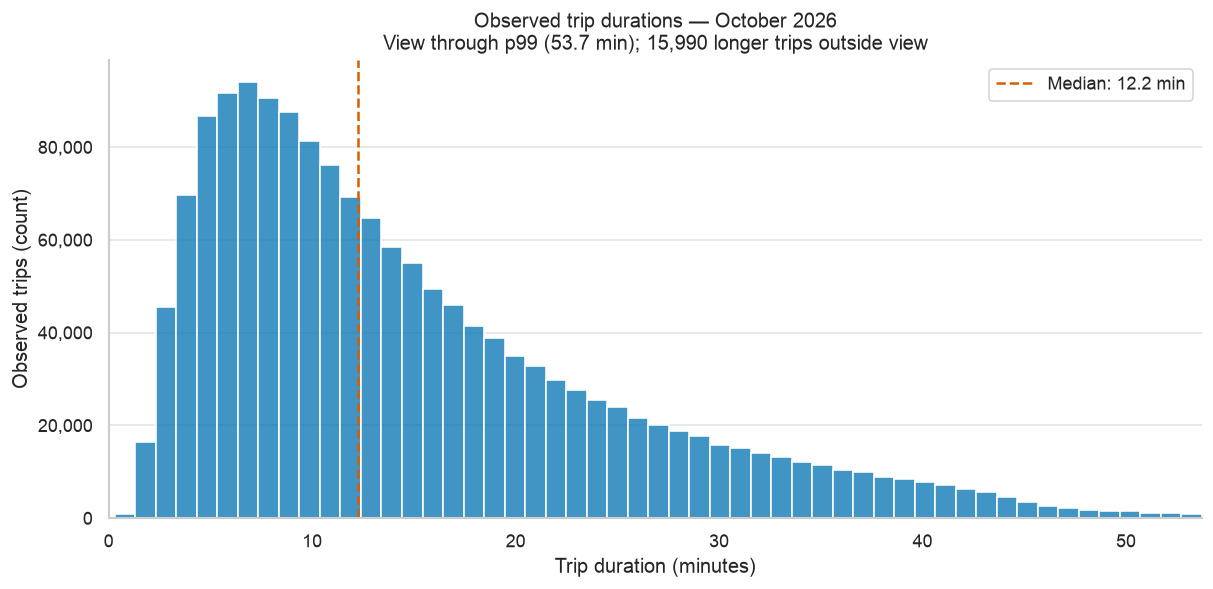

In [20]:
durations_october = october_pickups["duration_minutes"].dropna()
duration_p99 = durations_october.quantile(0.99)
duration_median = durations_october.median()
histogram_values = durations_october.loc[durations_october.le(duration_p99)]
hidden_tail_count = durations_october.gt(duration_p99).sum()

# Look for the typical duration range and the shape of the right tail.
fig, ax = plt.subplots(layout="constrained")
sns.histplot(histogram_values, binwidth=1, color=BLUE, edgecolor="white", ax=ax)
ax.axvline(duration_median, color=VERMILION, linestyle="--", label=f"Median: {duration_median:.1f} min")
ax.set(
    title=f"Observed trip durations — October 2026\nView through p99 ({duration_p99:.1f} min); {hidden_tail_count:,} longer trips outside view",
    xlabel="Trip duration (minutes)", ylabel="Observed trips (count)",
    xlim=(0, duration_p99),
)
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.legend()
plt.show()


### 2. Pickups by hour

Divide hourly counts by the number of calendar weekdays or weekend days, including days with zero events.


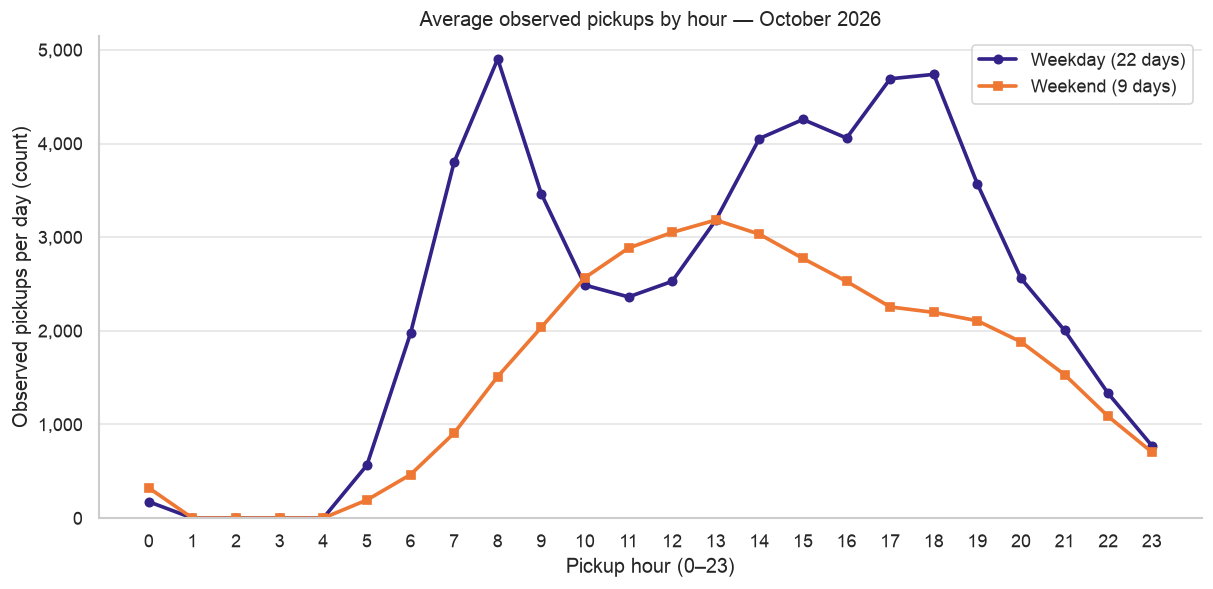

In [21]:
day_type_days = pd.Series(analysis_dates.dayofweek >= 5).value_counts().reindex([False, True], fill_value=0)
hourly_counts = pd.crosstab(october_pickups["pickup_is_weekend"], october_pickups["pickup_hour"])
hourly_counts = hourly_counts.reindex(index=[False, True], columns=range(24), fill_value=0)
hourly_average = hourly_counts.div(day_type_days, axis=0)
hourly_average.index = pd.Index(["Weekday", "Weekend"], name="day_type")

# Compare the timing and intensity of weekday and weekend pickup peaks.
fig, ax = plt.subplots(layout="constrained")
# Distinct marker shapes so the series do not rely on color alone.
for label, color, marker, weekend in [("Weekday", WEEKDAY, "o", False), ("Weekend", WEEKEND, "s", True)]:
    ax.plot(
        range(24), hourly_average.loc[label], color=color, linewidth=2.2, marker=marker, markersize=5,
        label=f"{label} ({day_type_days.loc[weekend]} days)",
    )
ax.set(
    title="Average observed pickups by hour — October 2026",
    xlabel="Pickup hour (0–23)", ylabel="Observed pickups per day (count)", ylim=(0, None),
)
ax.set_xticks(range(24))
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.legend()
plt.show()


### 3. Pickups by weekday and hour

Normalize each row by that weekday's calendar frequency to compare days fairly. A zero means no recorded pickups in that interval.


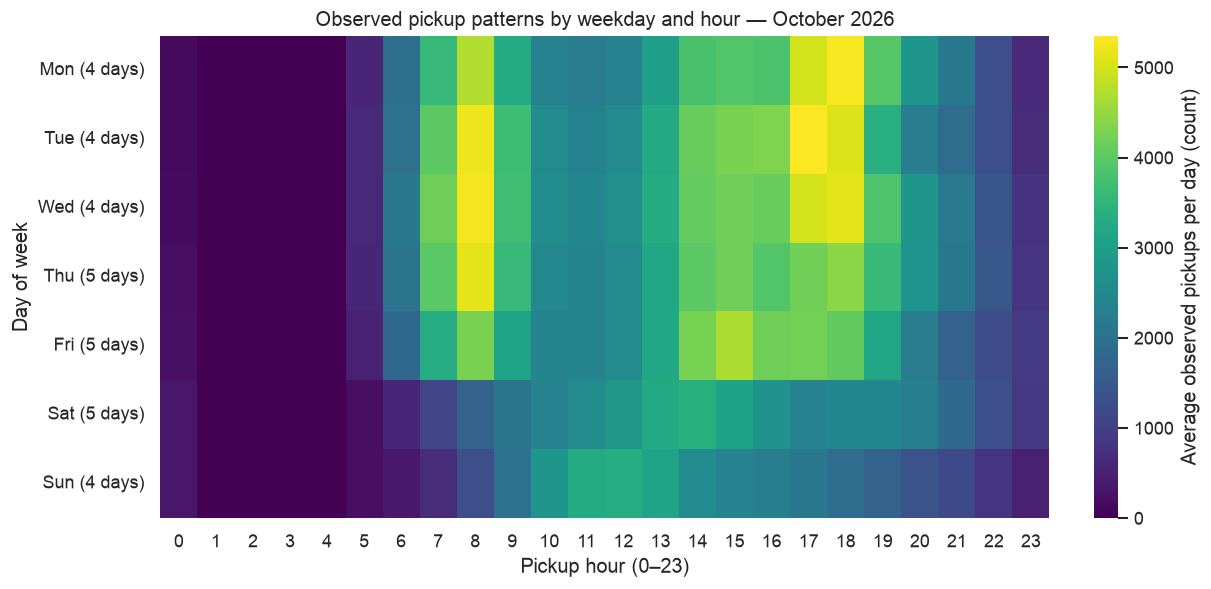

In [22]:
weekday_days = pd.Series(analysis_dates.dayofweek).value_counts().reindex(range(7), fill_value=0)
weekday_hour_counts = pd.crosstab(october_pickups["pickup_weekday"], october_pickups["pickup_hour"])
weekday_hour_counts = weekday_hour_counts.reindex(index=range(7), columns=range(24), fill_value=0)
weekday_hour_average = weekday_hour_counts.div(weekday_days, axis=0)
weekday_labels = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

# Look for recurring high-activity hours across the working week.
fig, ax = plt.subplots(layout="constrained")
sns.heatmap(
    weekday_hour_average, cmap="viridis", vmin=0, ax=ax,
    xticklabels=range(24),
    yticklabels=[f"{label} ({weekday_days.loc[i]} days)" for i, label in enumerate(weekday_labels)],
    cbar_kws={"label": "Average observed pickups per day (count)"},
)
ax.set(title="Observed pickup patterns by weekday and hour — October 2026", xlabel="Pickup hour (0–23)", ylabel="Day of week")
ax.tick_params(axis="both", labelrotation=0)
plt.show()


### 4. Daily pickups

Display every October date and distinguish weekend observations. Inspect low-count days before interpreting them as low demand.


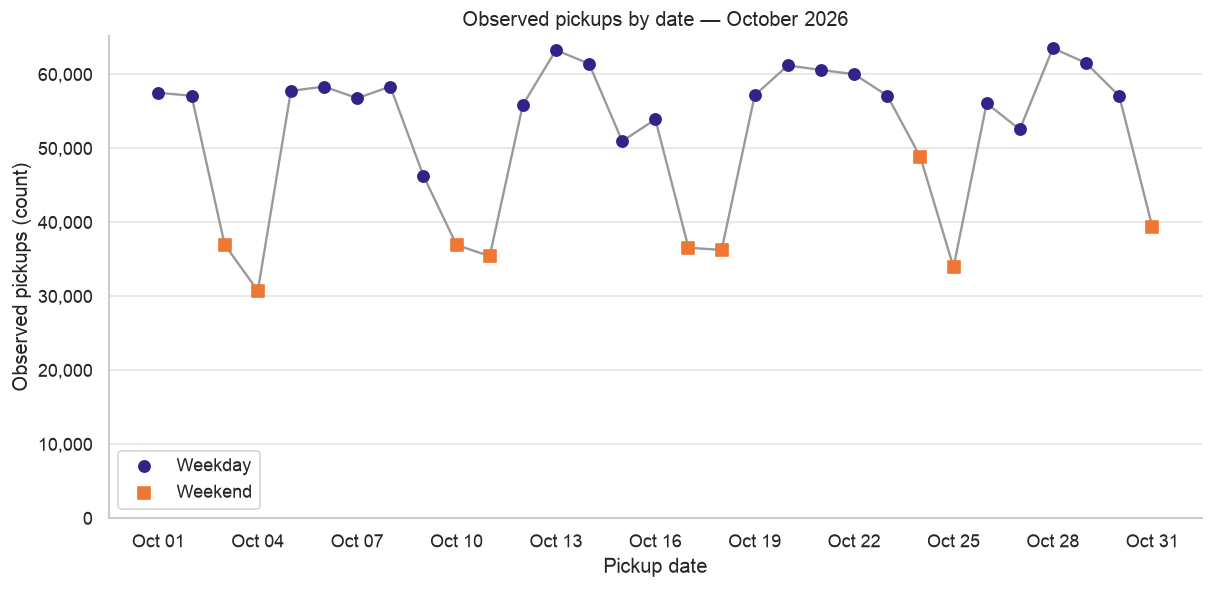

In [23]:
daily_pickups = october_pickups.groupby("pickup_date").size().reindex(analysis_dates, fill_value=0)
weekend_dates = analysis_dates.dayofweek >= 5

# Look for recurring weekday/weekend differences and unusual daily counts.
fig, ax = plt.subplots(layout="constrained")
ax.plot(daily_pickups.index, daily_pickups.values, color=GRAY, linewidth=1.4)
# Distinct marker shapes so the groups do not rely on color alone.
for mask, label, color, marker in [(~weekend_dates, "Weekday", WEEKDAY, "o"), (weekend_dates, "Weekend", WEEKEND, "s")]:
    ax.scatter(daily_pickups.index[mask], daily_pickups.values[mask], color=color, marker=marker, label=label, s=45, zorder=3)
ax.set(title="Observed pickups by date — October 2026", xlabel="Pickup date", ylabel="Observed pickups (count)", ylim=(0, None))
ax.xaxis.set_major_locator(mdates.DayLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.legend()
plt.show()


### 5. Most-used stations

Rank pickups and drop-offs separately using all October events in this file. These are activity rankings, not a contiguous subnetwork or a measure of imbalance.


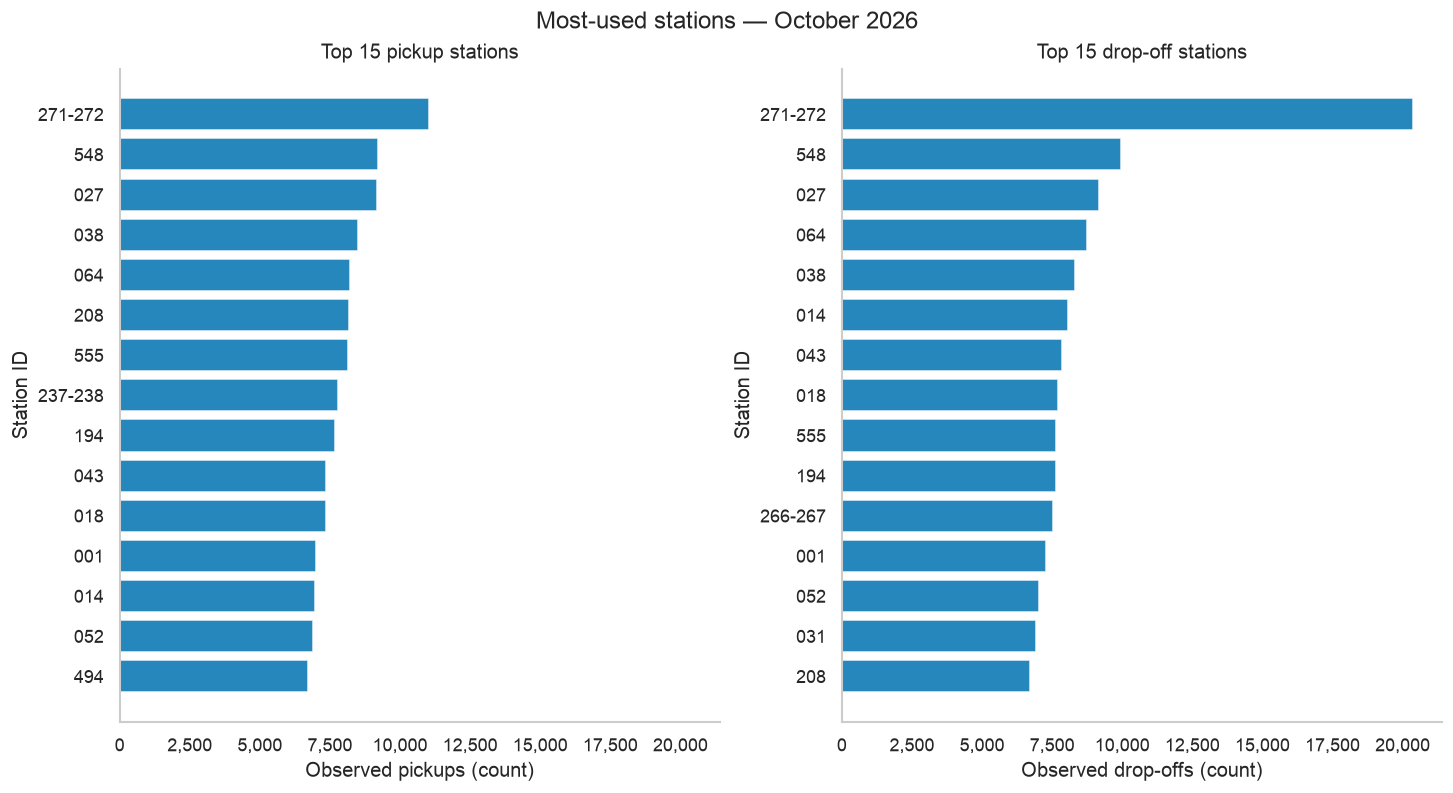

In [24]:
station_pickups = october_pickups["Ciclo_Estacion_Retiro"].value_counts()
station_dropoffs = october_dropoffs["Ciclo_EstacionArribo"].value_counts()
top_pickups = station_pickups.head(15)
top_dropoffs = station_dropoffs.head(15)

# Identify frequently used stations as candidates for later geographic review.
fig, axes = plt.subplots(1, 2, figsize=(12, 6.5), sharex=True, layout="constrained")
for ax, counts, title, event_label in [
    (axes[0], top_pickups, "Top 15 pickup stations", "pickups"),
    (axes[1], top_dropoffs, "Top 15 drop-off stations", "drop-offs"),
]:
    # Slightly lighter than the duration histogram; alpha keeps the hue blue.
    ax.barh(range(len(counts)), counts.values, color=BLUE, alpha=0.85)
    ax.set_yticks(range(len(counts)), labels=counts.index)
    ax.invert_yaxis()
    ax.set(title=title, xlabel=f"Observed {event_label} (count)", ylabel="Station ID")
    ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
    ax.grid(axis="y", visible=False)
fig.suptitle("Most-used stations — October 2026")
plt.show()


## Preliminary findings: October 2026

- Trip duration has a right tail: the median is 12.23 minutes and p75 is 20.48 minutes. The histogram omits 15,990 trips above p99 from view only.
- Weekdays average 57,469 observed pickups per day, versus 37,214 on weekends. Their hourly peaks occur at 08:00–09:00 and 13:00–14:00, respectively.
- The highest weekday-hour average is Tuesday, 17:00–18:00, with 5,350 observed pickups per Tuesday.
- Daily pickups range from 30,727 on October 4 to 63,534 on October 28. These counts alone do not explain the variation.
- Source identifier `271-272` leads both station rankings (11,026 pickups; 20,384 drop-offs). Verify composite identifiers against station metadata before selecting a geographic subnetwork.
